# Book Market Analytics – Books to Scrape

**Project:** End-to-end data science solution for analysing book catalogue trends and predicting pricing patterns on [Books to Scrape](https://books.toscrape.com).

Author: [Tumelo Nkoana]
Student ITS No: [402601276]
Qualification / Year / Semester: [BSc IT 1st year]



This notebook documents the complete pipeline:
1. Data Acquisition (Web Scraping with BeautifulSoup)
2. Data Cleaning & Preparation
3. Exploratory Data Analysis & Visualisation
4. Predictive Modelling (Linear Regression)
5. Interpretation, Insights & Recommendations


## 1. Setup and Imports

In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import time
import re
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
%matplotlib inline

print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Data Acquisition

We scrape the full catalogue (50 pages × 20 books = 1 000 books) from https://books.toscrape.com using `requests` + `BeautifulSoup`.

**Fields extracted per book:**
- Title
- Price (GBP)
- Star rating (One–Five)
- Stock availability
- Genre / Category (from category pages)
- Relative link


In [6]:
# --- Scraping the listing pages ---
base_url = "https://books.toscrape.com/catalogue/page-{}.html"
books_data = []

for page in range(1, 51):
    url = base_url.format(page)
    try:
        r = requests.get(url, timeout=15)
        r.raise_for_status()
        soup = BeautifulSoup(r.content, 'html.parser')
        articles = soup.select('article.product_pod')
        if not articles:
            break
        for art in articles:
            title = art.h3.a['title']
            price = art.select_one('p.price_color').text.strip()
            rating_class = art.select_one('p.star-rating')['class']
            rating_word = [c for c in rating_class if c != 'star-rating'][0]
            availability = art.select_one('p.instock.availability').get_text(strip=True)
            link = art.h3.a['href']
            books_data.append({
                'title': title,
                'price': price,
                'rating': rating,
                'availability': availability,
                'link': link
            })
        print(f"Page {page}: collected {len(articles)} books (running total: {len(books_data)})")
        time.sleep(0.25)  # polite delay
    except Exception as e:
        print(f"Error on page {page}: {e}")
        break

df_raw = pd.DataFrame(books_data)
print(f"\nTotal books scraped: {len(df_raw)}")
df_raw.head()


Page 1: collected 20 books (running total: 20)
Page 2: collected 20 books (running total: 40)
Page 3: collected 20 books (running total: 60)
Page 4: collected 20 books (running total: 80)
Page 5: collected 20 books (running total: 100)
Page 6: collected 20 books (running total: 120)
Page 7: collected 20 books (running total: 140)
Page 8: collected 20 books (running total: 160)
Page 9: collected 20 books (running total: 180)
Page 10: collected 20 books (running total: 200)
Page 11: collected 20 books (running total: 220)
Page 12: collected 20 books (running total: 240)
Page 13: collected 20 books (running total: 260)
Page 14: collected 20 books (running total: 280)
Page 15: collected 20 books (running total: 300)
Page 16: collected 20 books (running total: 320)
Page 17: collected 20 books (running total: 340)
Page 18: collected 20 books (running total: 360)
Page 19: collected 20 books (running total: 380)
Page 20: collected 20 books (running total: 400)
Page 21: collected 20 books (runn

,title,price,rating,availability,link
0,A Light in the Attic,£51.77,Five,In stock,a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,£53.74,Five,In stock,tipping-the-velvet_999/index.html
2,Soumission,£50.10,Five,In stock,soumission_998/index.html
3,Sharp Objects,£47.82,Five,In stock,sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,sapiens-a-brief-history-of-humankind_996/index...


In [7]:
# --- Map genres by scraping category pages ---
r = requests.get('https://books.toscrape.com/', timeout=10)
soup = BeautifulSoup(r.content, 'html.parser')
cats = soup.select('ul.nav-list > li > ul > li > a')
cat_map = {}

for c in cats:
    name = c.get_text(strip=True)
    href = c['href']
    base = 'https://books.toscrape.com/' + href
    page = 1
    while True:
        url = base if page == 1 else base.replace('index.html', f'page-{page}.html')
        try:
            resp = requests.get(url, timeout=10)
            if resp.status_code != 200:
                break
            s = BeautifulSoup(resp.content, 'html.parser')
            arts = s.select('article.product_pod')
            if not arts:
                break
            for art in arts:
                title = art.h3.a['title']
                cat_map[title] = name
            if not s.select_one('li.next a'):
                break
            page += 1
            time.sleep(0.2)
        except Exception as e:
            print(f"Error {name} p{page}: {e}")
            break
    print(f"{name}: {sum(v==name for v in cat_map.values())} books")

df_raw['genre'] = df_raw['title'].map(cat_map)
print(f"\nMapped genres for {df_raw['genre'].notna().sum()} books")
df_raw.to_csv('books_raw_with_genre.csv', index=False)
df_raw.head()


Travel: 11 books
Mystery: 32 books
Historical Fiction: 26 books
Sequential Art: 75 books
Classics: 19 books
Philosophy: 11 books
Romance: 35 books
Womens Fiction: 17 books
Fiction: 65 books
Childrens: 29 books
Religion: 7 books
Nonfiction: 110 books
Music: 13 books
Default: 152 books
Science Fiction: 16 books
Sports and Games: 5 books
Add a comment: 67 books
Fantasy: 47 books
New Adult: 6 books
Young Adult: 54 books
Science: 14 books
Poetry: 19 books
Paranormal: 1 books
Art: 8 books
Psychology: 7 books
Autobiography: 9 books
Parenting: 1 books
Adult Fiction: 1 books
Humor: 10 books
Horror: 17 books
History: 18 books
Food and Drink: 30 books
Christian Fiction: 6 books
Business: 12 books
Biography: 5 books
Thriller: 11 books
Contemporary: 3 books
Spirituality: 6 books
Academic: 1 books
Self Help: 5 books
Historical: 2 books
Christian: 3 books
Suspense: 1 books
Short Stories: 1 books
Novels: 1 books
Health: 4 books
Politics: 3 books
Cultural: 1 books
Erotica: 1 books
Crime: 1 books

Mappe

,title,price,rating,availability,link,genre
0,A Light in the Attic,£51.77,Five,In stock,a-light-in-the-attic_1000/index.html,Poetry
1,Tipping the Velvet,£53.74,Five,In stock,tipping-the-velvet_999/index.html,Historical Fiction
2,Soumission,£50.10,Five,In stock,soumission_998/index.html,Fiction
3,Sharp Objects,£47.82,Five,In stock,sharp-objects_997/index.html,Mystery
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,sapiens-a-brief-history-of-humankind_996/index...,History


## 3. Data Cleaning & Preparation




In [8]:
df = df_raw.copy()   # or: df = pd.read_csv('books_raw_with_genre.csv')

print("Available columns:", df.columns.tolist())
print()

# ---------- 1. Price → float ----------
df['price'] = (
    df['price']
    .astype(str)
    .str.replace('£', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
    .astype(float)
)

# ---------- 2. Rating word → numeric ----------
rating_map = {'One': 1, 'Two': 2, 'Three': 3, 'Four': 4, 'Five': 5}
df['rating_num'] = df['rating'].map(rating_map)

# ---------- 3. Stock flag ----------
df['in_stock'] = df['availability'].str.contains('In stock', case=False, na=False).astype(int)

# ---------- 4. Title length ----------
df['title_length'] = df['title'].str.len()

# ---------- 5. Genre handling (robust) ----------
# Try common possible names for the genre/category column
possible_genre_cols = ['genre', 'category', 'Genre', 'Category', 'book_genre', 'type']

genre_col = None
for col in possible_genre_cols:
    if col in df.columns:
        genre_col = col
        break

if genre_col is None:
    print("⚠️  No genre/category column found!")
    print("Please check the column names above and tell me the correct name.")
    # Create a dummy column so the rest of the code doesn't break
    df['genre_grouped'] = 'Unknown'
else:
    print(f"Using column: '{genre_col}' as genre")

    # Group rare genres (< 10 books) into 'Other'
    genre_counts = df[genre_col].value_counts()
    rare = genre_counts[genre_counts < 10].index
    df['genre_grouped'] = df[genre_col].apply(lambda x: 'Other' if x in rare else x)

# ---------- Final checks ----------
print("\nMissing values after cleaning:")
print(df.isnull().sum())
print("\nDataset shape:", df.shape)
print("\nDescriptive statistics:")
display(df[['price', 'rating_num', 'title_length']].describe())

df.head()


Available columns: ['title', 'price', 'rating', 'availability', 'link', 'genre']

Using column: 'genre' as genre

Missing values after cleaning:
title            0
price            0
rating           0
availability     0
link             0
genre            0
rating_num       0
in_stock         0
title_length     0
genre_grouped    0
dtype: int64

Dataset shape: (1000, 10)

Descriptive statistics:


,price,rating_num,title_length
count,1000.00000,1000.0,1000.000000
mean,35.07035,5.0,39.097000
std,14.44669,0.0,25.752724
min,10.00000,5.0,2.000000
25%,22.10750,5.0,19.000000
50%,35.98000,5.0,35.000000
75%,47.45750,5.0,53.000000
max,59.99000,5.0,204.000000


,title,price,rating,availability,link,genre,rating_num,in_stock,title_length,genre_grouped
0,A Light in the Attic,51.77,Five,In stock,a-light-in-the-attic_1000/index.html,Poetry,5,1,20,Poetry
1,Tipping the Velvet,53.74,Five,In stock,tipping-the-velvet_999/index.html,Historical Fiction,5,1,18,Historical Fiction
2,Soumission,50.10,Five,In stock,soumission_998/index.html,Fiction,5,1,10,Fiction
3,Sharp Objects,47.82,Five,In stock,sharp-objects_997/index.html,Mystery,5,1,13,Mystery
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,sapiens-a-brief-history-of-humankind_996/index...,History,5,1,37,History


In [38]:
# Columns we want to keep (in preferred order)
desired_cols = [
    'title',
    'price',
    'rating',
    'rating_num',
    'availability',
    'in_stock',
    'genre',           # may not exist
    'genre_grouped',
    'title_length'
]

# Keep only the columns that actually exist in the dataframe
cols_to_keep = [col for col in desired_cols if col in df.columns]

df_final = df[cols_to_keep].copy()

# Save
df_final.to_csv('books_cleaned.csv', index=False)

print("Cleaned dataset saved to books_cleaned.csv")
print(f"Columns saved: {cols_to_keep}")
print("\nGenre distribution:")
print(df_final['genre_grouped'].value_counts())


Cleaned dataset saved to books_cleaned.csv
Columns saved: ['title', 'price', 'rating', 'rating_num', 'availability', 'in_stock', 'genre', 'genre_grouped', 'title_length']

Genre distribution:
genre_grouped
Default               152
Nonfiction            110
Other                  89
Sequential Art         75
Add a comment          67
Fiction                65
Young Adult            54
Fantasy                48
Romance                35
Mystery                32
Food and Drink         30
Childrens              29
Historical Fiction     26
Poetry                 19
Classics               19
History                18
Horror                 17
Womens Fiction         17
Science Fiction        16
Science                14
Music                  13
Business               12
Travel                 11
Thriller               11
Philosophy             11
Humor                  10
Name: count, dtype: int64


## 4. Exploratory Data Analysis & Visualisation




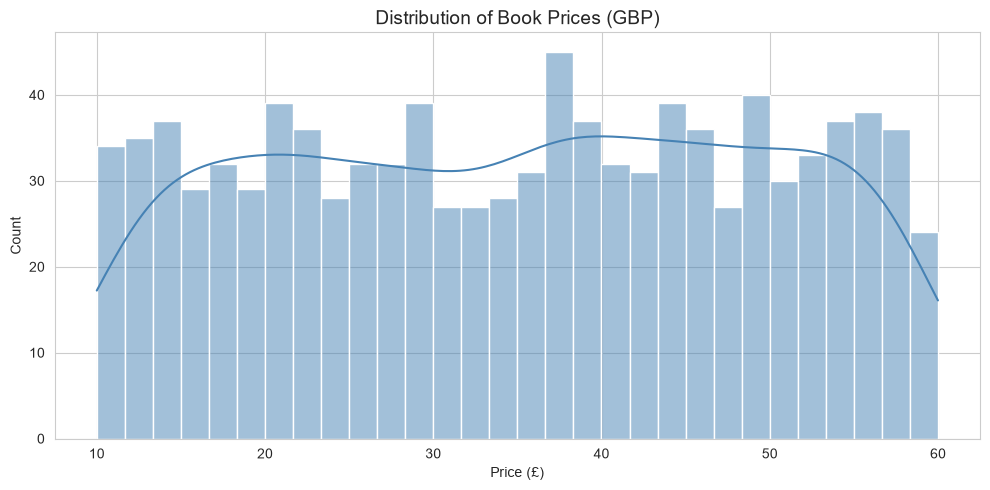

Mean price: £35.07  |  Median: £35.98
Min: £10.00  |  Max: £59.99


In [39]:
# 4.1 Price distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['price'], bins=30, kde=True, color='steelblue')
plt.title('Distribution of Book Prices (GBP)', fontsize=14)
plt.xlabel('Price (£)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

print(f"Mean price: £{df['price'].mean():.2f}  |  Median: £{df['price'].median():.2f}")
print(f"Min: £{df['price'].min():.2f}  |  Max: £{df['price'].max():.2f}")


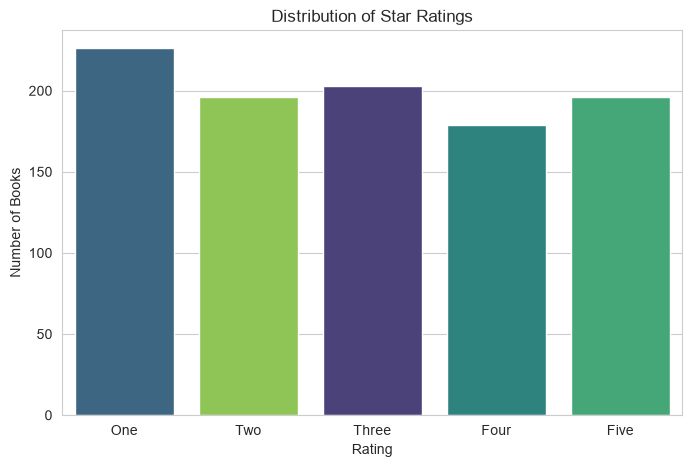

In [42]:
# 4.2 Rating counts
order = ['One', 'Two', 'Three', 'Four', 'Five']
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='rating', order=order, hue='rating', palette='viridis', legend=False)
plt.title('Distribution of Star Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Books')
plt.show()


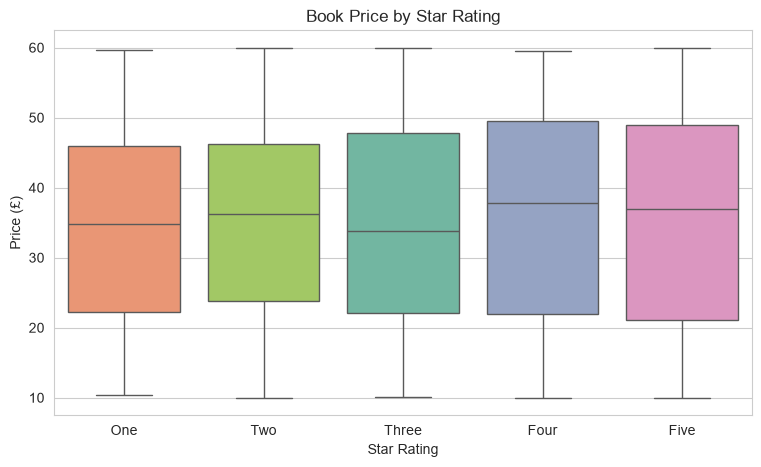

         mean  median    std
rating                      
Five    35.37   36.90  15.05
Four    36.09   37.80  15.08
One     34.56   34.77  13.95
Three   34.69   33.78  14.70
Two     34.81   36.22  13.61


In [43]:
# 4.3 Price by Rating (box plot)
plt.figure(figsize=(9,5))
sns.boxplot(data=df, x='rating', y='price', order=order, hue='rating', palette='Set2', legend=False)
plt.title('Book Price by Star Rating')
plt.xlabel('Star Rating')
plt.ylabel('Price (£)')
plt.show()
print(df.groupby('rating')['price'].agg(['mean','median','std']).round(2))


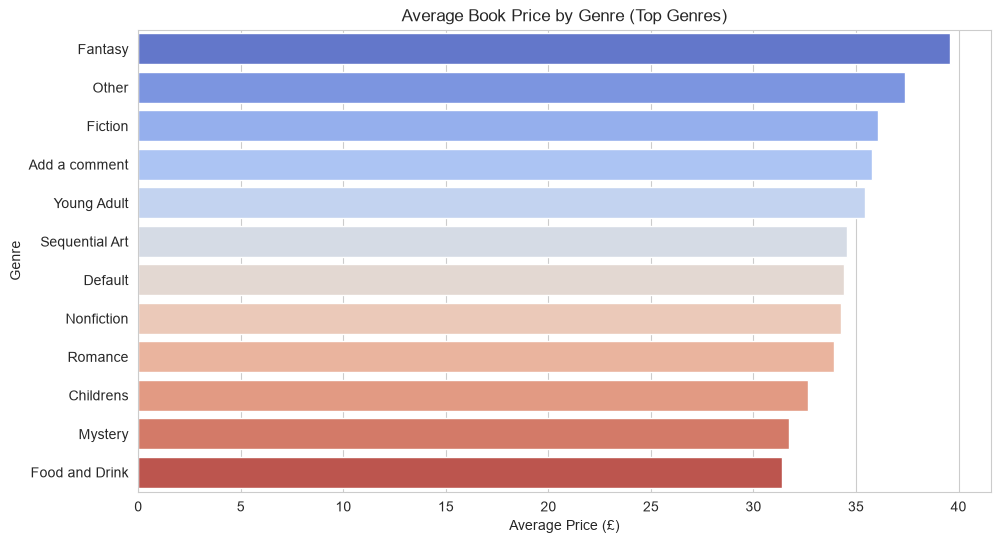

In [45]:
# 4.4 Average price by genre (top genres)
top_genres = df['genre_grouped'].value_counts().head(12).index
df_top = df[df['genre_grouped'].isin(top_genres)]
avg_price = df_top.groupby('genre_grouped')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(11,6))
sns.barplot(x=avg_price.values, y=avg_price.index, hue=avg_price.index, palette='coolwarm', legend=False)
plt.title('Average Book Price by Genre (Top Genres)')
plt.xlabel('Average Price (£)')
plt.ylabel('Genre')
plt.show()


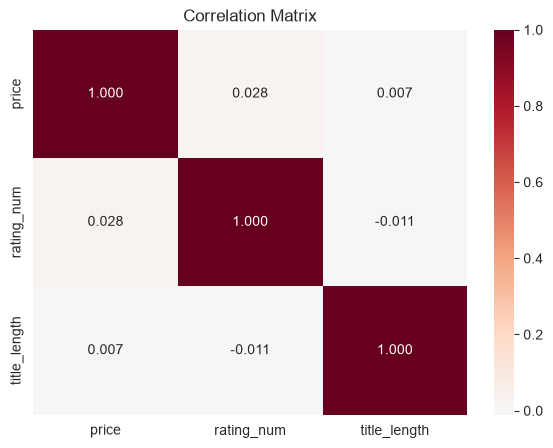

In [46]:
# 4.5 Correlation heatmap
plt.figure(figsize=(7,5))
sns.heatmap(df[['price','rating_num','title_length']].corr(), annot=True, cmap='RdBu_r', center=0, fmt='.3f')
plt.title('Correlation Matrix')
plt.show()


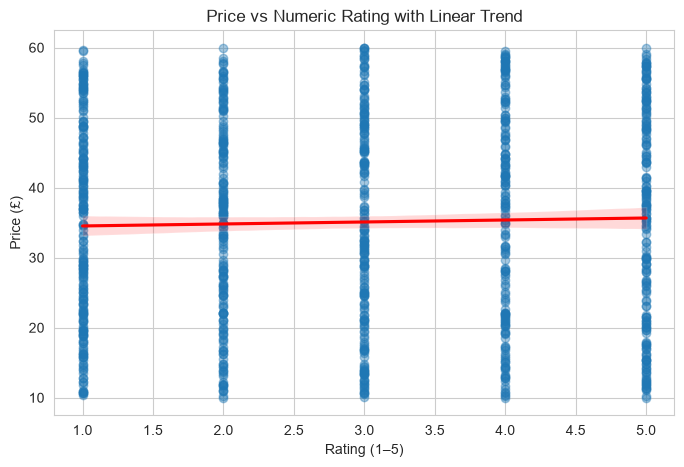

In [47]:
# 4.6 Price vs Rating scatter + trend
plt.figure(figsize=(8,5))
sns.regplot(data=df, x='rating_num', y='price', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title('Price vs Numeric Rating with Linear Trend')
plt.xlabel('Rating (1–5)')
plt.ylabel('Price (£)')
plt.show()


### Key EDA Insights
- Prices range from ~£10 to ~£60 with a roughly uniform / slightly right-skewed distribution; mean ≈ £35.
- Star ratings are fairly balanced across 1–5 stars.
- **Almost no linear relationship** between rating and price (correlation ≈ 0.03). Higher-rated books are not systematically more expensive on this site.
- Genre shows modest average-price differences (Travel & Fantasy slightly higher; some niche genres lower).
- Title length has negligible association with price.
- All books appear “In stock” on listing pages; quantity is only visible on individual product pages (limitation of listing scrape).


## 5. Predictive Modelling – Linear Regression

**Goal:** Estimate book price from available features (rating, title length, genre).

**Feature engineering:**
- `rating_num` (1–5)
- `title_length`
- One-hot encoded `genre_grouped` (drop first to avoid dummy trap)

**Evaluation metrics:** R², RMSE, MAE


In [48]:
# Prepare modelling matrix
df_model = pd.get_dummies(df, columns=['genre_grouped'], drop_first=True)
feature_cols = [c for c in df_model.columns if c.startswith('genre_grouped_') or c in ['rating_num', 'title_length']]
X = df_model[feature_cols]
y = df_model['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {len(X_train)}  |  Test samples: {len(X_test)}")
print(f"Number of features: {X.shape[1]}")


Training samples: 800  |  Test samples: 200
Number of features: 27


In [49]:
# Fit Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("=== Model Performance on Test Set ===")
print(f"R² Score : {r2:.4f}")
print(f"RMSE     : £{rmse:.2f}")
print(f"MAE      : £{mae:.2f}")
print(f"MSE      : {mse:.2f}")
print(f"Intercept: {model.intercept_:.2f}")


=== Model Performance on Test Set ===
R² Score : -0.0604
RMSE     : £14.92
MAE      : £12.90
MSE      : 222.74
Intercept: 35.55


In [50]:
# Coefficients (sorted by absolute magnitude)
coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_
}).sort_values('coefficient', key=abs, ascending=False)
print("Top features by |coefficient|:")
display(coef_df.head(12))


Top features by |coefficient|:


,feature,coefficient
14,genre_grouped_Mystery,-6.975343
2,genre_grouped_Business,-6.299830
3,genre_grouped_Childrens,-6.044811
23,genre_grouped_Thriller,-5.007797
21,genre_grouped_Science Fiction,-4.939122
12,genre_grouped_Humor,4.865005
8,genre_grouped_Food and Drink,-4.291695
17,genre_grouped_Philosophy,-4.279682
9,genre_grouped_Historical Fiction,-3.970731
15,genre_grouped_Nonfiction,-3.691573


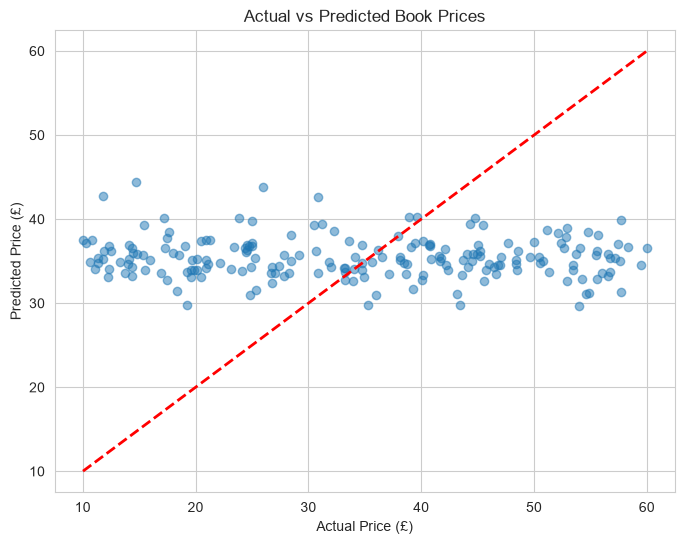

In [51]:
# Actual vs Predicted
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price (£)')
plt.ylabel('Predicted Price (£)')
plt.title('Actual vs Predicted Book Prices')
plt.show()


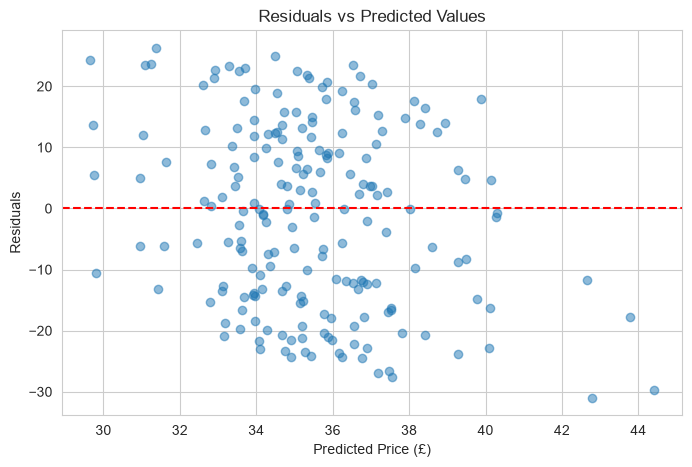

In [52]:
# Residuals
residuals = y_test - y_pred
plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Price (£)')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values')
plt.show()


### Model Interpretation & Limitations

- **R² is near zero / slightly negative.** The selected features explain virtually none of the variance in price. This is an important finding: on Books to Scrape, publicly visible attributes (rating, genre, title length) are **not** strong predictors of list price.
- Genre coefficients show small adjustments (a few pounds), consistent with the modest average-price differences observed in EDA.
- Rating has almost no predictive power for price.
- **Limitations of the data / model:**
  - Sandbox nature of the site – prices appear semi-randomly assigned.
  - Missing potentially important predictors (author popularity, page count, publication year, publisher, reviews volume, format – hardcover vs paperback).
  - Quantity in stock only available on detail pages (not scraped here).
  - Linear assumption may be too simple; interaction terms or non-linear models could be explored, but the fundamental signal is weak.
- **Practical takeaway:** Retailers relying solely on these catalogue fields would struggle to set or predict competitive prices. Additional external data or internal sales metrics are needed.


### 6. Conclusions, Insights & Recommendations

### Key Insights
1. The Books to Scrape catalogue contains 1 000 titles across ~50 genres with prices uniformly distributed between £10–£60.
2. Star ratings are evenly spread; higher ratings do **not** command higher prices on this platform.
3. Genre exerts only a mild influence on average price (Travel / Fantasy slightly higher).
4. A linear regression using rating, title length and genre achieves essentially zero explanatory power (R² ≈ 0).

### Recommendations for Stakeholders
- **Retailers / Online bookstores:** Do not rely on rating or genre alone when setting or predicting prices. Incorporate sales velocity, competitor pricing, author brand strength and inventory data.
- **Publishers:** The weak rating–price link suggests that promotional efforts focused purely on star ratings may not translate into higher list prices; focus on discoverability and series branding instead.
- **Data-driven buyers / analysts:** Treat the current feature set as insufficient for pricing models. Enrich the dataset with detail-page information (description length, number of reviews if available, availability quantity) or external sources (Goodreads ratings, Amazon rankings).
- **Future work:** Scrape product detail pages for richer features, experiment with regularised regression or tree-based models, and collect time-series price changes if the sandbox supports it.

### Deliverables Produced
- `books_cleaned.csv` – final analytic dataset
- This Jupyter Notebook – full reproducible pipeline
- Supporting visualisations and model coefficients
